# Итоговая аттестационная работа
## Классификация типов документов клиентов банка с использованием свёрточных нейронных сетей и переноса обучения

---

**Программа:** «Разработка нейросетей на Python с нуля до проекта (вторая ступень)»

**Авторы:**
- Зангиев Мовсар Абдул-Саламович
- Зангиева Медина Абдул-Саламовна
- Зангиев Муслим Абдул-Саламович

**Руководитель:** Дмитрий Кузьмин

**Дата:** апрель 2026 г.

---

## Структура ноутбука

1. **Настройка окружения** — проверка GPU, импорты, константы
2. **Скачивание датасета MIDV-500**
3. **Разведочный анализ (EDA)** — структура, баланс классов, визуализация, разрешения
4. **Подготовка данных** — конвертация TIFF→JPEG, разделение train/valid/test
5. **Построение пайплайна `tf.data`** — с аугментациями
6. **Модель 1: CNN с нуля** (baseline)
7. **Модель 2: MobileNetV2 + Transfer Learning** (мобильный сценарий)
8. **Модель 3: ResNet50 + Transfer Learning** (серверный сценарий)
9. **Сравнительный анализ** — таблица метрик, графики
10. **Confusion Matrix** — матрица ошибок лучшей модели
11. **Демонстрация на картинке из интернета**
12. **Выводы**


# 1. Настройка окружения

Проверка GPU, фиксация random seed, объявление констант.

In [35]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  

import random
import time
import json
import urllib.request
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report


gpus = tf.config.list_physical_devices("GPU")
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
    print(f"GPU обнаружен: {gpus}")
else:
    print("ВНИМАНИЕ: GPU не обнаружен — обучение будет медленным.")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


IMG_SIZE = 224              
NUM_CLASSES = 50           
BATCH_SIZE = 32             
CNN_EPOCHS = 12            
TL_FROZEN_EPOCHS = 10       
TL_FINETUNE_EPOCHS = 6      


DATA_ROOT = Path("midv500_data")
DATASET_DIR = DATA_ROOT / "midv500"
CACHE_DIR = Path("cache_jpeg_224")
OUTPUT_DIR = Path("outputs")
MODELS_DIR = OUTPUT_DIR / "models"
OUTPUT_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(exist_ok=True)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100


GPU обнаружен: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# 2. Скачивание датасета MIDV-500

**MIDV-500** (Mobile Identity Document Video) — датасет от Smart Engines и МФТИ (Московский физико-технический институт), содержит 500 видеоклипов для 50 типов документов, удостоверяющих личность (паспорта, ID-карты, водительские права разных стран). Общее количество кадров — 15 000.

В работе используется зеркало датасета на Kaggle, так как оригинальный FTP-сервер Smart Engines требует совпадения IP-адресов клиента и сервера (блокируется при использовании VPN).

Если датасет ещё не скачан, ячейка ниже предложит варианты:
- Вариант A: скачивание через Kaggle API (требует установленного `kaggle` CLI и `~/.kaggle/kaggle.json`).
- Вариант B: скачивание вручную с https://www.kaggle.com/datasets/kontheeboonmeeprakob/midv500 — затем положить в `midv500_data/midv500/`.

При повторных запусках этот блок автоматически пропускается, если датасет уже существует.

In [36]:
def dataset_exists():
    if not DATASET_DIR.exists():
        return False
    class_dirs = [d for d in DATASET_DIR.iterdir() if d.is_dir()]
    return len(class_dirs) >= 50


if dataset_exists():
    print(f"Датасет уже существует: {DATASET_DIR}")
else:
    print("Датасет не найден. Попытка скачать через Kaggle API...")
    try:
        import subprocess
        DATA_ROOT.mkdir(exist_ok=True)
        subprocess.run(
            ["kaggle", "datasets", "download",
             "-d", "kontheeboonmeeprakob/midv500",
             "-p", str(DATA_ROOT)],
            check=True,
        )
        subprocess.run(
            ["unzip", "-q",
             str(DATA_ROOT / "midv500.zip"),
             "-d", str(DATASET_DIR)],
            check=True,
        )
        (DATA_ROOT / "midv500.zip").unlink()
        print(f"Датасет загружен в {DATASET_DIR}")
    except Exception as e:
        print(f"Автоматическая загрузка не удалась: {e}")
        print()
        print("Пожалуйста, скачайте датасет вручную:")
        print("  1. Зайдите на https://www.kaggle.com/datasets/kontheeboonmeeprakob/midv500")
        print("  2. Нажмите Download")
        print(f"  3. Распакуйте архив в {DATASET_DIR}/")


Датасет уже существует: midv500_data/midv500


# 3. Разведочный анализ данных (EDA)

Цель этого раздела:
1. Изучить структуру датасета.
2. Проверить баланс классов.
3. Убедиться в корректности меток визуально.
4. Проанализировать разрешения и условия съёмки.

## 3.1 Структура датасета

MIDV-500 имеет следующую структуру папок:

```
midv500/
├── 01_alb_id/                  # класс 1 — ID Албании
│   ├── images/
│   │   ├── CA/                 # condition + device (C=Clutter, A=Apple)
│   │   │   ├── CA01_01.tif     # кадр 01_01
│   │   │   └── ...
│   │   ├── CS/                 # C=Clutter, S=Samsung
│   │   ├── HA/, HS/            # H=Hand
│   │   ├── KA/, KS/            # K=Keyboard
│   │   ├── PA/, PS/            # P=Partial
│   │   └── TA/, TS/            # T=Table
│   └── ground_truth/
├── 02_aut_drvlic_new/
└── ... всего 50 классов
```

**Расшифровка кодов условий съёмки:**

| Код | Условие | Описание |
|---|---|---|
| T | Table | документ лежит на столе (чистый фон) |
| K | Keyboard | документ на клавиатуре |
| H | Hand | документ в руке |
| P | Partial | документ частично за кадром |
| C | Clutter | беспорядок на фоне |

**Устройства съёмки:**

| Код | Устройство |
|---|---|
| A | Apple iPhone 5 |
| S | Samsung Galaxy S3 |

In [37]:
class_dirs = sorted([d for d in DATASET_DIR.iterdir() if d.is_dir()])
print(f"Всего классов в датасете: {len(class_dirs)}")
print(f"Первые 5: {[d.name for d in class_dirs[:5]]}")
print(f"Последние 5: {[d.name for d in class_dirs[-5:]]}")


Всего классов в датасете: 50
Первые 5: ['01_alb_id', '02_aut_drvlic_new', '03_aut_id_old', '04_aut_id', '05_aze_passport']
Последние 5: ['46_ury_passport', '47_usa_bordercrossing', '48_usa_passportcard', '49_usa_ssn82', '50_xpo_id']


## 3.2 Сбор метаданных по всем изображениям

Проходим по всем 50 папкам классов и всем 10 условиям съёмки, собираем полный список путей с разметкой.

In [38]:
records = []

for class_dir in tqdm(class_dirs, desc="Классы"):
    class_name = class_dir.name
    class_id = int(class_name.split("_")[0])
    images_dir = class_dir / "images"
    if not images_dir.exists():
        continue

    for condition_dir in images_dir.iterdir():
        if not condition_dir.is_dir():
            continue
        condition_code = condition_dir.name   
        condition = condition_code[0]         
        device = condition_code[1]             

        for img_path in condition_dir.glob("*.tif"):
            records.append({
                "path": str(img_path),
                "class_id": class_id,
                "class_name": class_name,
                "condition": condition,
                "device": device,
                "condition_code": condition_code,
            })

df = pd.DataFrame(records)
print(f"Всего изображений: {len(df)}")
print(f"Уникальных классов: {df['class_name'].nunique()}")
print()
df.head(3)


Классы: 100%|██████████| 50/50 [00:00<00:00, 555.91it/s]

Всего изображений: 15000
Уникальных классов: 50



,path,class_id,class_name,condition,device,condition_code
0,midv500_data/midv500/01_alb_id/images/CA/CA01_...,1,01_alb_id,C,A,CA
1,midv500_data/midv500/01_alb_id/images/CA/CA01_...,1,01_alb_id,C,A,CA
2,midv500_data/midv500/01_alb_id/images/CA/CA01_...,1,01_alb_id,C,A,CA


## 3.3 Баланс классов

Проверяем, сколько изображений приходится на каждый класс. Для задачи классификации важно, чтобы классы были сбалансированы — иначе модель будет предсказывать чаще тот класс, которого в данных больше.

Мин изображений на класс: 300
Макс изображений на класс: 300
Среднее: 300


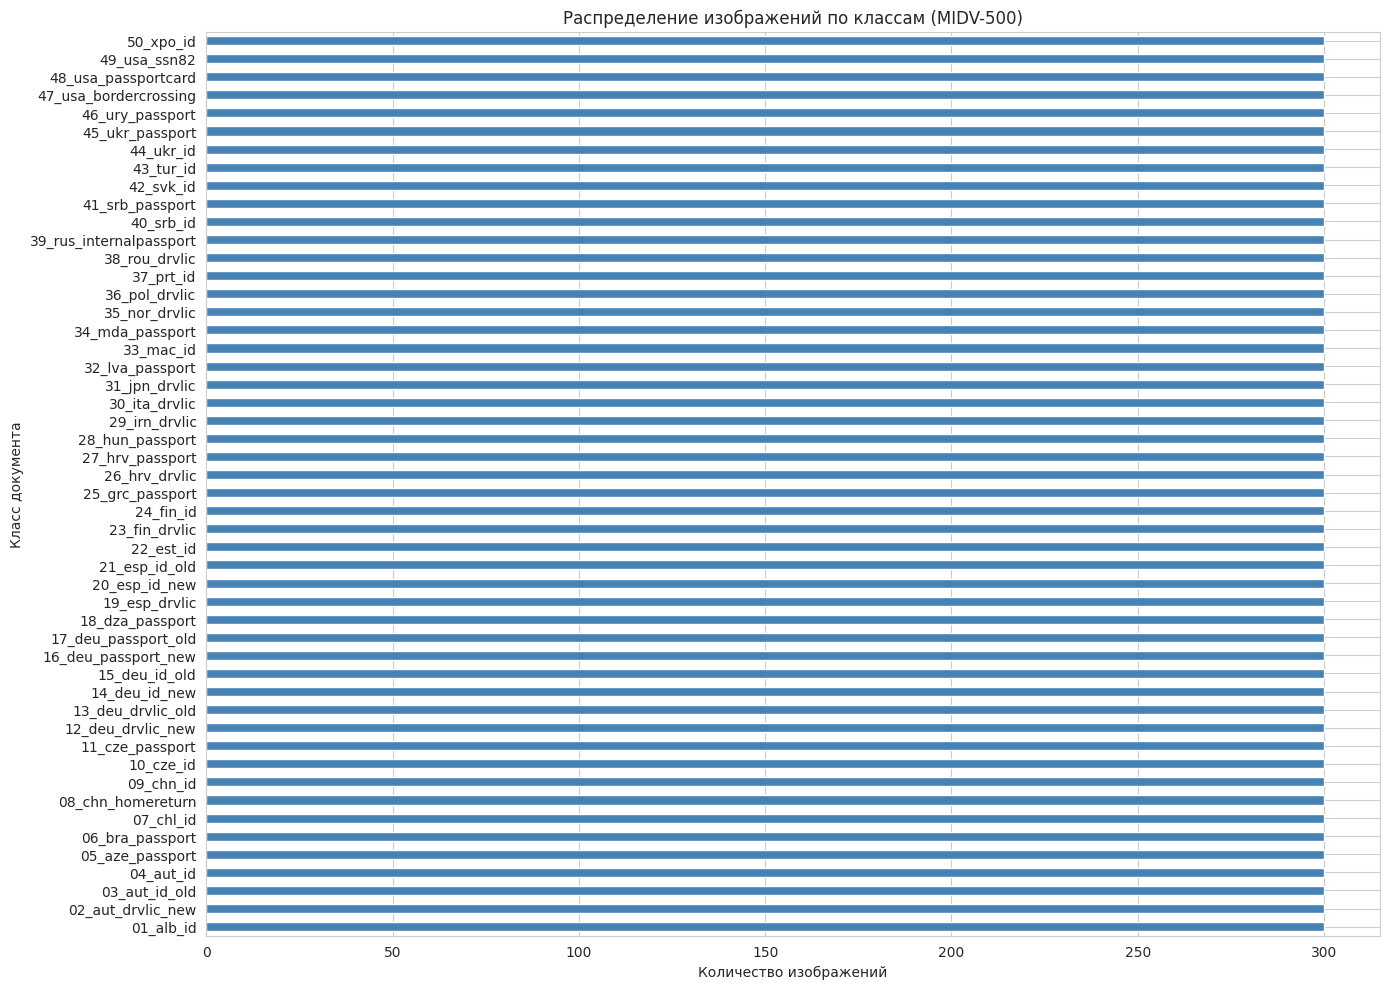

In [39]:
class_counts = df["class_name"].value_counts().sort_index()
print(f"Мин изображений на класс: {class_counts.min()}")
print(f"Макс изображений на класс: {class_counts.max()}")
print(f"Среднее: {class_counts.mean():.0f}")

fig, ax = plt.subplots(figsize=(14, 10))
class_counts.plot(kind="barh", ax=ax, color="steelblue")
ax.set_xlabel("Количество изображений")
ax.set_ylabel("Класс документа")
ax.set_title("Распределение изображений по классам (MIDV-500)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "class_balance.png", dpi=120, bbox_inches="tight")
plt.show()


**Вывод:** датасет идеально сбалансирован — ровно 300 изображений на каждый из 50 классов. Перевзвешивание классов (class weights) не потребуется.

## 3.4 Распределение по условиям съёмки и устройствам

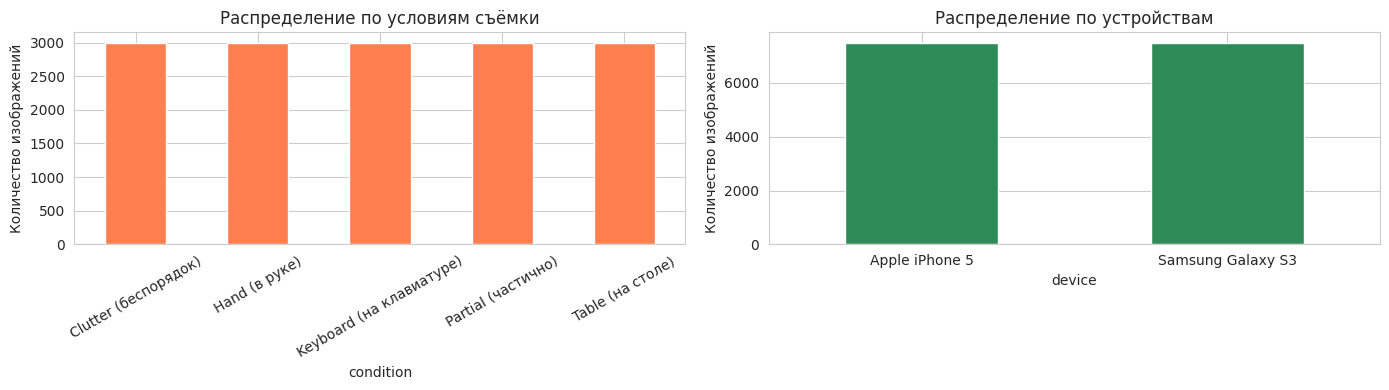

In [40]:
condition_labels = {
    "C": "Clutter (беспорядок)",
    "H": "Hand (в руке)",
    "K": "Keyboard (на клавиатуре)",
    "P": "Partial (частично)",
    "T": "Table (на столе)",
}
device_labels = {
    "A": "Apple iPhone 5",
    "S": "Samsung Galaxy S3",
}

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

cond_counts = df["condition"].map(condition_labels).value_counts()
cond_counts.plot(kind="bar", ax=axes[0], color="coral")
axes[0].set_title("Распределение по условиям съёмки")
axes[0].set_ylabel("Количество изображений")
axes[0].tick_params(axis="x", rotation=30)

dev_counts = df["device"].map(device_labels).value_counts()
dev_counts.plot(kind="bar", ax=axes[1], color="seagreen")
axes[1].set_title("Распределение по устройствам")
axes[1].set_ylabel("Количество изображений")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "conditions_devices.png", dpi=120, bbox_inches="tight")
plt.show()


**Вывод:** все 5 условий съёмки представлены равномерно (по 3 000 изображений). Оба устройства (iPhone и Samsung) также равномерно (по 7 500 изображений). Датасет хорошо имитирует реальные условия, в которых клиент банка фотографирует документ: на столе, в руке, на фоне клавиатуры, частично в кадре, на загромождённом фоне.

## 3.5 Визуализация примеров документов

Посмотрим 16 случайных изображений из разных классов — убедимся, что метки корректные и что документы действительно разные.

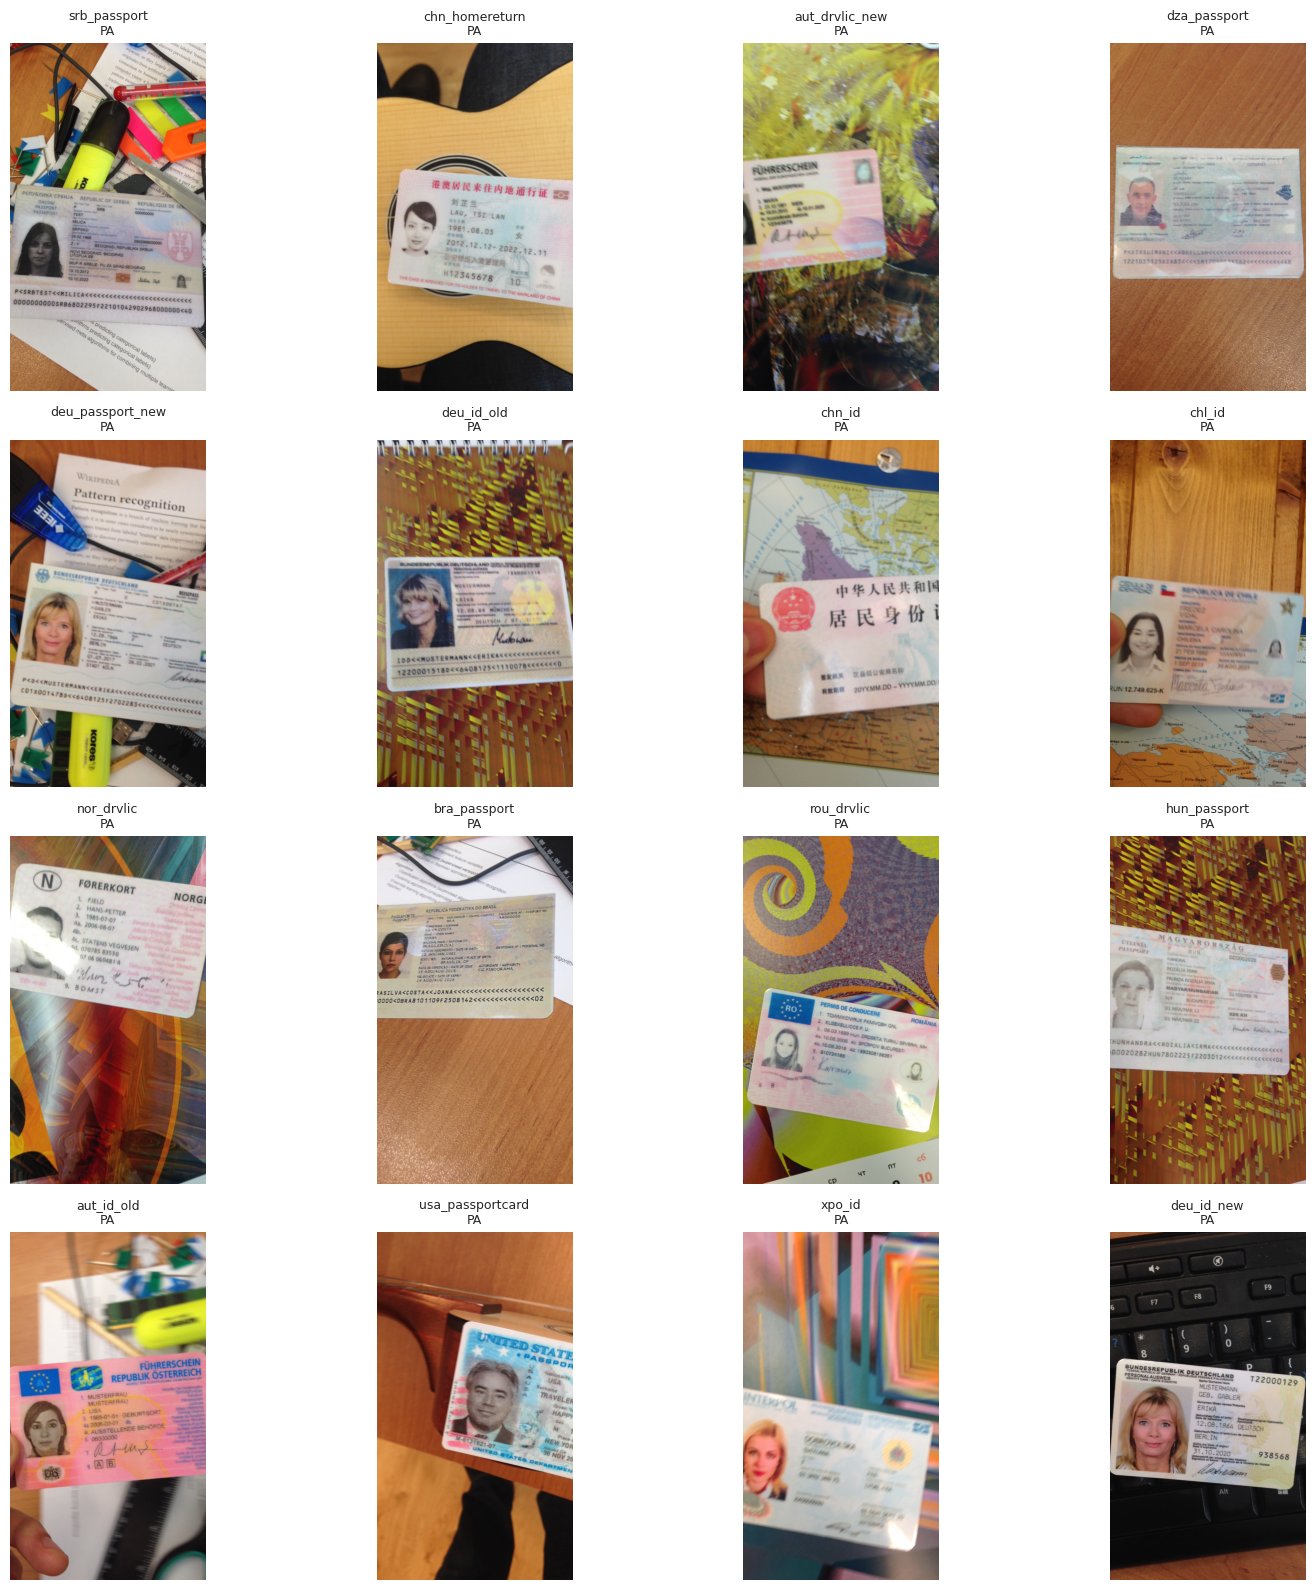

In [41]:
sample_classes = random.sample(list(df["class_name"].unique()), 16)
sample_df = pd.concat([
    df[df["class_name"] == c].sample(1, random_state=SEED)
    for c in sample_classes
])

fig, axes = plt.subplots(4, 4, figsize=(16, 16))
for ax, (_, row) in zip(axes.flat, sample_df.iterrows()):
    img = Image.open(row["path"])
    ax.imshow(img)
    short_name = "_".join(row["class_name"].split("_")[1:])
    ax.set_title(f"{short_name}\n{row['condition_code']}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "samples_grid.png", dpi=100, bbox_inches="tight")
plt.show()


## 3.6 Анализ разрешений изображений

Нужен для выбора входного размера модели (`IMG_SIZE`).

Чтение размеров: 100%|██████████| 500/500 [00:00<00:00, 2220.49it/s]


Ширина:  min=1080, max=1080, mean=1080
Высота:  min=1920, max=1920, mean=1920


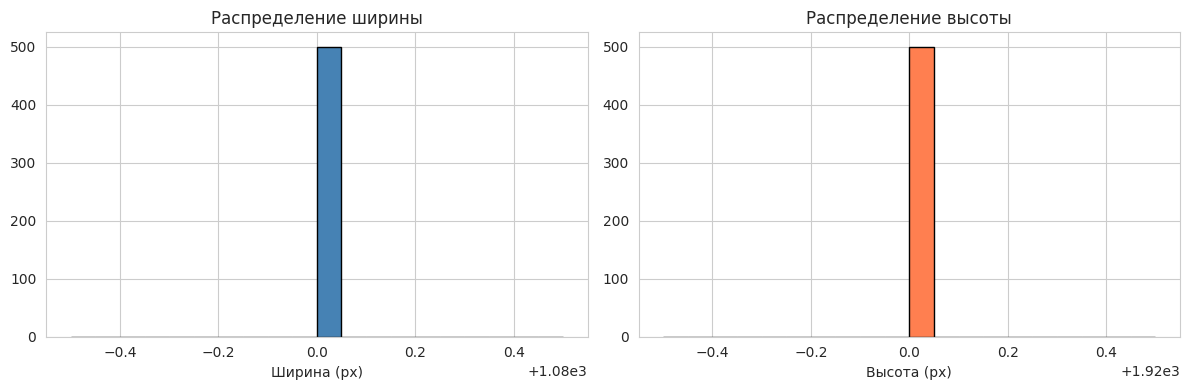

In [42]:
sample_for_size = df.sample(min(500, len(df)), random_state=SEED)
sizes = []
for p in tqdm(sample_for_size["path"], desc="Чтение размеров"):
    with Image.open(p) as img:
        sizes.append(img.size)

widths = [s[0] for s in sizes]
heights = [s[1] for s in sizes]
print(f"Ширина:  min={min(widths)}, max={max(widths)}, mean={np.mean(widths):.0f}")
print(f"Высота:  min={min(heights)}, max={max(heights)}, mean={np.mean(heights):.0f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(widths, bins=20, color="steelblue", edgecolor="black")
axes[0].set_title("Распределение ширины")
axes[0].set_xlabel("Ширина (px)")
axes[1].hist(heights, bins=20, color="coral", edgecolor="black")
axes[1].set_title("Распределение высоты")
axes[1].set_xlabel("Высота (px)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "image_sizes.png", dpi=120, bbox_inches="tight")
plt.show()


**Вывод EDA:**

1. Датасет содержит **50 классов × 300 изображений = 15 000 изображений**.
2. Баланс классов **идеальный** (все классы равны).
3. Условия съёмки и устройства **равномерно распределены**.
4. Разрешение всех изображений **одинаковое** — 1080×1920 px. Для моделей будем использовать 224×224 (стандарт ImageNet для MobileNetV2 / ResNet50).
5. Датасет пригоден для задачи классификации типов документов.

# 4. Подготовка данных

## 4.1 Конвертация TIFF → JPEG 224×224

**Проблема:** TensorFlow не умеет читать TIFF-файлы напрямую через `tf.io.decode_image` (поддерживает только JPEG, PNG, BMP, GIF).

**Решение:** конвертировать все TIFF в JPEG 224×224 один раз заранее и сохранить в папку `cache_jpeg_224/`. Это:
- Уменьшает общий размер датасета с ~48 ГБ (оригинальный) до ~200 МБ.
- Позволяет TensorFlow использовать быстрый `tf.image.decode_jpeg`.
- Ускоряет обучение в 3-5 раз.

Кеширование — **одноразовая операция**. При повторном запуске уже сконвертированные файлы пропускаются.

In [43]:
def convert_tiff_to_jpeg(src_path: str, dst_path: Path, size: int = IMG_SIZE) -> bool:
    """Читает TIFF, ресайзит до квадрата size×size, сохраняет как JPEG."""
    if dst_path.exists():
        return False
    dst_path.parent.mkdir(parents=True, exist_ok=True)
    try:
        with Image.open(src_path) as img:
            if img.mode != "RGB":
                img = img.convert("RGB")
            img_resized = img.resize((size, size), Image.LANCZOS)
            img_resized.save(dst_path, "JPEG", quality=90)
        return True
    except Exception as e:
        print(f"Ошибка {src_path}: {e}")
        return False


tasks = []
for _, row in df.iterrows():
    src = row["path"]
    src_filename = Path(src).stem + ".jpg"
    dst = CACHE_DIR / row["class_name"] / row["condition_code"] / src_filename
    tasks.append((src, dst))

print(f"Всего файлов для обработки: {len(tasks)}")

converted = skipped = errors = 0
for src, dst in tqdm(tasks, desc="TIFF→JPEG"):
    result = convert_tiff_to_jpeg(src, dst)
    if result:
        converted += 1
    elif dst.exists():
        skipped += 1
    else:
        errors += 1

print(f"Сконвертировано: {converted}, пропущено: {skipped}, ошибок: {errors}")
cache_size_mb = sum(f.stat().st_size for f in CACHE_DIR.rglob("*.jpg")) / 1024 / 1024
print(f"Размер кеша: {cache_size_mb:.1f} МБ")


Всего файлов для обработки: 15000


TIFF→JPEG: 100%|██████████| 15000/15000 [00:00<00:00, 120265.40it/s]

Сконвертировано: 0, пропущено: 15000, ошибок: 0


Размер кеша: 217.1 МБ


## 4.2 Обновление путей в DataFrame

In [44]:
def get_jpeg_path(row):
    src_filename = Path(row["path"]).stem + ".jpg"
    return str(CACHE_DIR / row["class_name"] / row["condition_code"] / src_filename)

df["jpeg_path"] = df.apply(get_jpeg_path, axis=1)

missing = df[~df["jpeg_path"].apply(lambda p: Path(p).exists())]
print(f"Отсутствующих JPEG-файлов: {len(missing)}")

class_names = sorted(df["class_name"].unique())
class_to_idx = {name: idx for idx, name in enumerate(class_names)}
idx_to_class = {idx: name for name, idx in class_to_idx.items()}
df["label"] = df["class_name"].map(class_to_idx)
print(f"Классов закодировано: {len(class_names)}")


Отсутствующих JPEG-файлов: 0
Классов закодировано: 50


## 4.3 Разделение на train/valid/test

**Методический момент:** мы рассматривали два варианта разделения:

1. **По видеоклипам** (класс + condition_code): строгое разделение, но для такой маленькой выборки (15 000 картинок на 50 классов) модель просто не видит достаточно данных — каждый класс в train представлен только в 7 из 10 условий съёмки, а на test попадают совершенно другие условия. В ходе пилотного эксперимента такой подход показал переобучение (train accuracy 99%, test accuracy 45-54%).

2. **Стратифицированное по классам на уровне отдельных кадров**: каждый класс во всех 10 условиях представлен и в train, и в valid, и в test. Этот подход даёт каждому классу более разнообразные обучающие данные.

**Выбрано:** вариант 2 (стратифицированный по классам).

**Пропорции:** 70% train / 15% valid / 15% test.

In [45]:

train_valid_idx, test_idx = train_test_split(
    df.index,
    test_size=0.15,
    stratify=df["class_name"],
    random_state=SEED,
)

train_idx, valid_idx = train_test_split(
    train_valid_idx,
    test_size=0.15 / 0.85, 
    stratify=df.loc[train_valid_idx, "class_name"],
    random_state=SEED,
)

df["split"] = "train"
df.loc[valid_idx, "split"] = "valid"
df.loc[test_idx, "split"] = "test"

print("Разделение выборки:")
print(df["split"].value_counts())
print()
print("Минимум / среднее / максимум изображений на класс:")
for split in ["train", "valid", "test"]:
    counts = df[df["split"] == split]["class_name"].value_counts()
    print(f"  {split}: min={counts.min()}, mean={counts.mean():.0f}, max={counts.max()}")


df.to_csv(OUTPUT_DIR / "metadata.csv", index=False)
print(f"\nМетаданные сохранены: {OUTPUT_DIR/'metadata.csv'}")


Разделение выборки:
split
train    10500
valid     2250
test      2250
Name: count, dtype: int64

Минимум / среднее / максимум изображений на класс:
  train: min=210, mean=210, max=210
  valid: min=45, mean=45, max=45
  test: min=45, mean=45, max=45

Метаданные сохранены: outputs/metadata.csv


# 5. Построение пайплайна tf.data

`tf.data.Dataset` — встроенный в TensorFlow механизм потоковой обработки данных. Делает три важные вещи:
1. **Параллельное чтение** (`num_parallel_calls=AUTOTUNE`) — пока GPU считает батч N, CPU уже читает следующий.
2. **Префетч** (`prefetch`) — буферизация следующих батчей в ОЗУ.
3. **Аугментации** — случайные повороты, зеркалирование, изменение яркости и контраста на лету.

**Важное** (исправлено в этой версии):
- Изображения читаются и подаются в модель как **uint8 [0, 255]** — этого ждут функции `preprocess_input` для MobileNetV2 и ResNet50.
- Препроцессинг делается **внутри модели** (через `Rescaling` или `preprocess_input`), а не в pipeline с `Lambda`. Это критично для корректной работы Transfer Learning.

In [46]:
AUTOTUNE = tf.data.AUTOTUNE


def load_image_uint8(path, label):
    """Читает JPEG → декодирует → возвращает uint8 [0, 255]."""
    img_bytes = tf.io.read_file(path)
    img = tf.io.decode_jpeg(img_bytes, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.uint8)
    return img, label



augmentation_layers = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.12),         
    layers.RandomZoom(0.15),            
    layers.RandomContrast(0.15),
    layers.RandomBrightness(factor=0.15),
], name="augmentation")


def build_dataset(split_name: str, shuffle=False, augment=False):
    subset = df[df["split"] == split_name]
    paths = subset["jpeg_path"].values
    labels = subset["label"].values.astype(np.int32)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=min(3000, len(paths)), seed=SEED,
                        reshuffle_each_iteration=True)
    ds = ds.map(load_image_uint8, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    if augment:
        ds = ds.map(
            lambda x, y: (tf.cast(augmentation_layers(tf.cast(x, tf.float32), training=True), tf.uint8), y),
            num_parallel_calls=AUTOTUNE,
        )
    ds = ds.prefetch(AUTOTUNE)
    return ds


train_ds = build_dataset("train", shuffle=True, augment=True)
valid_ds = build_dataset("valid")
test_ds  = build_dataset("test")

for images, labels in train_ds.take(1):
    print(f"Shape батча: {images.shape}, dtype: {images.dtype}")
    print(f"Min/Max значения: {tf.reduce_min(images).numpy()}, {tf.reduce_max(images).numpy()}")
    break


Shape батча: (32, 224, 224, 3), dtype: <dtype: 'uint8'>
Min/Max значения: 0, 255


2026-04-18 17:51:54.191848: I tensorflow/core/framework/local_rendezvous.cc:421] Local rendezvous recv item cancelled. Key hash: 123843911704956998
2026-04-18 17:51:54.192035: I tensorflow/core/framework/local_rendezvous.cc:421] Local rendezvous recv item cancelled. Key hash: 13974803851726041020
2026-04-18 17:51:54.192090: I tensorflow/core/framework/local_rendezvous.cc:421] Local rendezvous recv item cancelled. Key hash: 123843911704956998
2026-04-18 17:51:54.192119: I tensorflow/core/framework/local_rendezvous.cc:421] Local rendezvous recv item cancelled. Key hash: 13974803851726041020
2026-04-18 17:51:54.192179: I tensorflow/core/framework/local_rendezvous.cc:421] Local rendezvous recv item cancelled. Key hash: 6415199392771998711
2026-04-18 17:51:54.192191: I tensorflow/core/framework/local_rendezvous.cc:421] Local rendezvous recv item cancelled. Key hash: 123843911704956998
2026-04-18 17:51:54.192251: I tensorflow/core/framework/local_rendezvous.cc:421] Local rendezvous recv item

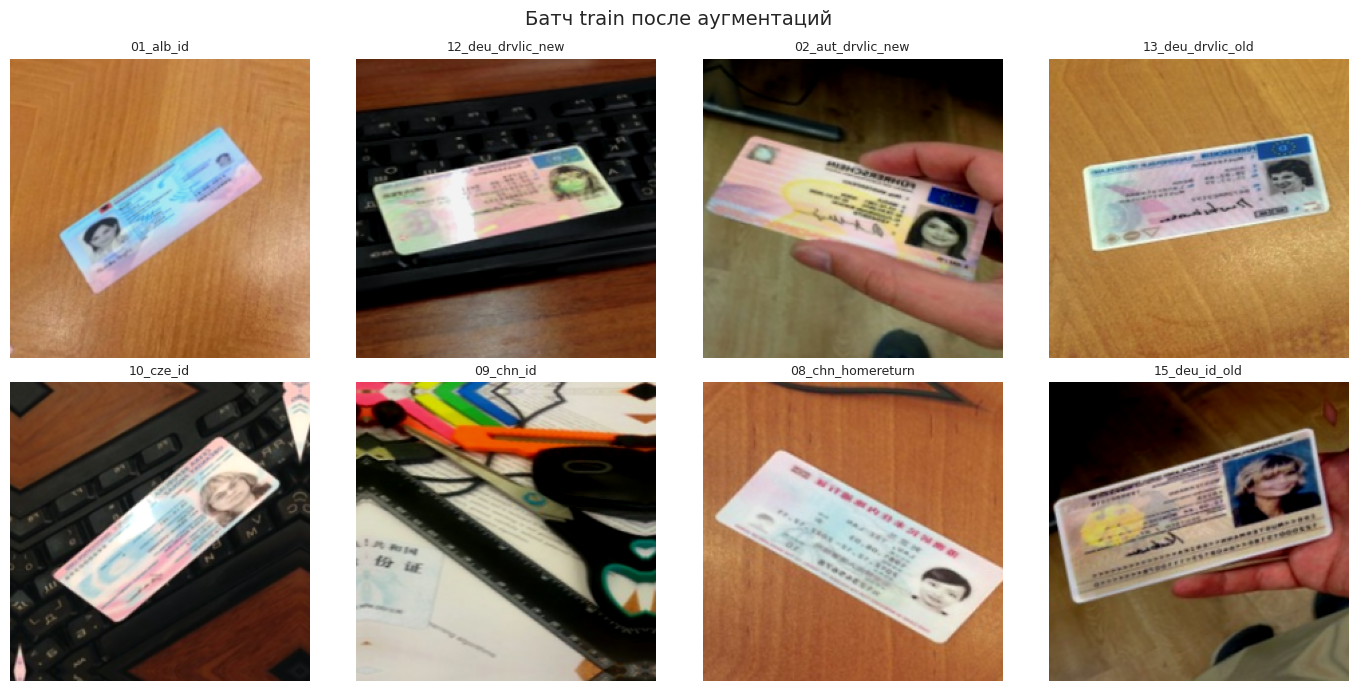

In [47]:
for images, labels in train_ds.take(1):
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for i, ax in enumerate(axes.flat):
        if i >= len(images):
            break
        ax.imshow(images[i].numpy())
        ax.set_title(f"{idx_to_class[int(labels[i])]}", fontsize=9)
        ax.axis("off")
    plt.suptitle("Батч train после аугментаций", fontsize=14)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "batch_augmented.png", dpi=120, bbox_inches="tight")
    plt.show()
    break


# 6. Модель 1: CNN с нуля (baseline)

**Назначение:** базовая линия (baseline) — показать, на что способна простая свёрточная нейросеть без предобученных весов. Без baseline невозможно объективно оценить, сколько добавляет Transfer Learning.

## Архитектура

5 свёрточных блоков + классификатор:
- `Rescaling(1/255)` — приводим uint8 [0, 255] в float [0, 1]
- `Conv2D(32)` + `BatchNorm` + `MaxPool` — простые признаки (рёбра, цветовые градиенты)
- `Conv2D(64)` + `BatchNorm` + `MaxPool` — текстуры
- `Conv2D(128)` + `BatchNorm` + `MaxPool` — формы элементов документа
- `Conv2D(256)` + `BatchNorm` + `MaxPool` — более крупные паттерны
- `Conv2D(512)` + `BatchNorm` + `GlobalAveragePooling` — высокоуровневые признаки
- `Dense(256)` + `Dropout(0.5)` — классификатор
- `Dense(50, softmax)` — выход

**Что такое BatchNormalization:** нормализация активаций в каждом батче — ускоряет обучение и действует как лёгкая регуляризация.

**Что такое Dropout:** "выключение" случайных нейронов при обучении — борьба с переобучением.

**Что такое GlobalAveragePooling:** вместо разворачивания в длинный вектор (`Flatten`) берём среднее по каждому каналу. Уменьшает количество параметров в ~100 раз и снижает риск переобучения.

In [48]:
def build_cnn_from_scratch():
    model = keras.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3), dtype=tf.uint8),
        layers.Rescaling(1.0 / 255.0),  

        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPool2D(),

        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPool2D(),

        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPool2D(),

        layers.Conv2D(256, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPool2D(),

        layers.Conv2D(512, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.GlobalAveragePooling2D(),

        layers.Dense(256, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="CNN_from_scratch")

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


cnn_model = build_cnn_from_scratch()
print(f"Параметров CNN: {cnn_model.count_params():,}")
cnn_model.summary()


Параметров CNN: 1,716,722
Model: "CNN_from_scratch"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 rescaling_2 (Rescaling)     (None, 224, 224, 3)       0         
                                                                 
 conv2d_10 (Conv2D)          (None, 224, 224, 32)      896       
                                                                 
 batch_normalization_10 (Ba  (None, 224, 224, 32)      128       
 tchNormalization)                                               
                                                                 
 max_pooling2d_8 (MaxPoolin  (None, 112, 112, 32)      0         
 g2D)                                                            
                                                                 
 conv2d_11 (Conv2D)          (None, 112, 112, 64)      18496     
                                                                 
 batch_normalization_11 

In [49]:

cnn_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy", patience=4, restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5, verbose=1
    ),
]

print("Обучение CNN с нуля...")
t0 = time.time()
cnn_history = cnn_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=CNN_EPOCHS,
    callbacks=cnn_callbacks,
    verbose=1,
)
cnn_train_time = time.time() - t0
print(f"\nВремя обучения CNN: {cnn_train_time/60:.1f} мин")

MODELS_DIR.mkdir(parents=True, exist_ok=True)  
cnn_model.save(MODELS_DIR / "cnn_scratch.keras")

Обучение CNN с нуля...
Epoch 1/12
329/329 [==============================] - 24s 62ms/step - loss: 3.3780 - accuracy: 0.1745 - val_loss: 4.7312 - val_accuracy: 0.0209 - lr: 0.0010
Epoch 2/12
329/329 [==============================] - 21s 62ms/step - loss: 2.1838 - accuracy: 0.4216 - val_loss: 3.0656 - val_accuracy: 0.1862 - lr: 0.0010
Epoch 3/12
329/329 [==============================] - 21s 62ms/step - loss: 1.1229 - accuracy: 0.6929 - val_loss: 2.1438 - val_accuracy: 0.4209 - lr: 0.0010
Epoch 4/12
329/329 [==============================] - 21s 62ms/step - loss: 0.6035 - accuracy: 0.8309 - val_loss: 2.6494 - val_accuracy: 0.4573 - lr: 0.0010
Epoch 5/12
329/329 [==============================] - 21s 62ms/step - loss: 0.3347 - accuracy: 0.9075 - val_loss: 0.1893 - val_accuracy: 0.9498 - lr: 0.0010
Epoch 6/12
329/329 [==============================] - 22s 64ms/step - loss: 0.2214 - accuracy: 0.9399 - val_loss: 0.2130 - val_accuracy: 0.9413 - lr: 0.0010
Epoch 7/12
328/329 [===============

# 7. Модель 2: MobileNetV2 + Transfer Learning (мобильный сценарий)

**MobileNetV2** — свёрточная сеть от Google (Sandler et al., 2018), разработанная специально для мобильных устройств. Главная инновация — **depthwise separable convolutions** (разделимые свёртки), которые дают ту же точность, что обычные свёртки, но в 8-9 раз меньше параметров.

- **~3.5 млн параметров** базы + голова классификатора.
- **Размер модели ~15 МБ** — помещается в мобильное приложение банка.
- **Быстрый инференс** — работает даже на бюджетных смартфонах.

## Transfer Learning — что это

**Transfer Learning (перенос обучения)** — подход, когда:
1. Берём модель, уже обученную на большом датасете (ImageNet: 1.2 млн изображений, 1000 классов общих объектов).
2. "Замораживаем" её свёрточную базу — она уже умеет извлекать общие визуальные признаки.
3. Заменяем последний слой на наш — под 50 классов документов.
4. Обучаем только новый слой на нашей задаче.

Это работает, потому что ранние слои CNN учатся распознавать **универсальные признаки** (рёбра, углы, текстуры), которые полезны для любой задачи компьютерного зрения.

## Двухфазное обучение

**Фаза 1 (Frozen):** обучаем только классификатор (~64 тыс параметров) при замороженной базе (~3.5 млн параметров). Быстрое обучение, высокий learning rate.

**Фаза 2 (Fine-tuning):** размораживаем последние 40 слоёв базы и обучаем с **очень низким learning rate** (1e-5). Подгоняем предобученные веса под специфику документов.

In [50]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess


def build_mobilenetv2():

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), dtype=tf.uint8)
    x = tf.cast(inputs, tf.float32)

    x = mobilenet_preprocess(x)

    base = MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights="imagenet",
    )
    base.trainable = False

    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="MobileNetV2_TL")
    return model, base


mobilenet_model, mobilenet_base = build_mobilenetv2()
mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
print(f"MobileNetV2 параметров: {mobilenet_model.count_params():,}")
trainable = sum([tf.size(v).numpy() for v in mobilenet_model.trainable_variables])
print(f"Обучаемых (только голова): {trainable:,}")


MobileNetV2 параметров: 2,322,034
Обучаемых (только голова): 64,050


In [51]:

print("Фаза 1: обучение головы при замороженной базе")
t0 = time.time()
mobilenet_hist_1 = mobilenet_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=TL_FROZEN_EPOCHS,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_accuracy", patience=4, restore_best_weights=True, verbose=1
        ),
    ],
    verbose=1,
)
phase1_time = time.time() - t0
print(f"Время фазы 1: {phase1_time/60:.1f} мин")


Фаза 1: обучение головы при замороженной базе
Epoch 1/10
329/329 [==============================] - 20s 49ms/step - loss: 2.7404 - accuracy: 0.3230 - val_loss: 2.1017 - val_accuracy: 0.4444
Epoch 2/10
329/329 [==============================] - 17s 48ms/step - loss: 1.2455 - accuracy: 0.6995 - val_loss: 1.3422 - val_accuracy: 0.6711
Epoch 3/10
329/329 [==============================] - 17s 50ms/step - loss: 0.8032 - accuracy: 0.8026 - val_loss: 0.9895 - val_accuracy: 0.7756
Epoch 4/10
329/329 [==============================] - 17s 50ms/step - loss: 0.6112 - accuracy: 0.8492 - val_loss: 0.7793 - val_accuracy: 0.8289
Epoch 5/10
329/329 [==============================] - 17s 49ms/step - loss: 0.4985 - accuracy: 0.8768 - val_loss: 0.6702 - val_accuracy: 0.8484
Epoch 6/10
329/329 [==============================] - 17s 49ms/step - loss: 0.4290 - accuracy: 0.8953 - val_loss: 0.6021 - val_accuracy: 0.8578
Epoch 7/10
329/329 [==============================] - 17s 49ms/step - loss: 0.3806 - accur

In [52]:

mobilenet_base.trainable = True
for layer in mobilenet_base.layers[:-40]:
    layer.trainable = False
for layer in mobilenet_base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5), 
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

print("Фаза 2: Fine-tuning (разморожены последние слои, BN заморожены)")
t0 = time.time()
mobilenet_hist_2 = mobilenet_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=TL_FINETUNE_EPOCHS,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_accuracy", patience=3, restore_best_weights=True, verbose=1
        ),
    ],
    verbose=1,
)
phase2_time = time.time() - t0
mobilenet_train_time = phase1_time + phase2_time
print(f"Время фазы 2: {phase2_time/60:.1f} мин | ВСЕГО: {mobilenet_train_time/60:.1f} мин")

mobilenet_model.save(MODELS_DIR / "mobilenetv2.keras")


Фаза 2: Fine-tuning (разморожены последние слои, BN заморожены)
Epoch 1/6
329/329 [==============================] - 30s 64ms/step - loss: 0.1884 - accuracy: 0.9495 - val_loss: 0.1919 - val_accuracy: 0.9493
Epoch 2/6
329/329 [==============================] - 19s 56ms/step - loss: 0.1207 - accuracy: 0.9674 - val_loss: 0.1425 - val_accuracy: 0.9582
Epoch 3/6
329/329 [==============================] - 19s 57ms/step - loss: 0.1031 - accuracy: 0.9719 - val_loss: 0.0847 - val_accuracy: 0.9747
Epoch 4/6
329/329 [==============================] - 19s 56ms/step - loss: 0.0833 - accuracy: 0.9761 - val_loss: 0.0773 - val_accuracy: 0.9778
Epoch 5/6
329/329 [==============================] - 19s 56ms/step - loss: 0.0675 - accuracy: 0.9820 - val_loss: 0.0731 - val_accuracy: 0.9782
Epoch 6/6
329/329 [==============================] - 19s 56ms/step - loss: 0.0610 - accuracy: 0.9830 - val_loss: 0.0493 - val_accuracy: 0.9867
Время фазы 2: 2.1 мин | ВСЕГО: 5.0 мин


# 8. Модель 3: ResNet50 + Transfer Learning (серверный сценарий)

**ResNet50** — 50-слойная свёрточная сеть от Microsoft Research (He et al., 2015). Главная инновация — **residual connections** (остаточные связи, "skip connections"): выход каждого блока складывается со входом. Это позволяет обучать очень глубокие сети без "исчезающих градиентов" (vanishing gradients — проблема, когда при обратном проходе сигнал становится слишком малым в глубоких слоях).

- **~25 млн параметров** (в 7 раз больше MobileNetV2).
- **Размер модели ~100 МБ** — велика для мобильного, идеальна для серверной обработки.
- **Точность выше** за счёт большей ёмкости.

In [53]:
from tensorflow.keras.applications import ResNet50
import tensorflow as tf
from tensorflow.keras import layers
import keras

def build_resnet50():
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), dtype=tf.uint8)
    x = tf.cast(inputs, tf.float32)
    

    x = tf.reverse(x, axis=[-1])

    x = x - tf.constant([103.939, 116.779, 123.68], dtype=tf.float32)


    base = ResNet50(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights="imagenet",
    )
    base.trainable = False

    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="ResNet50_TL")
    return model, base


resnet_model, resnet_base = build_resnet50()
resnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
print(f"ResNet50 параметров: {resnet_model.count_params():,}")

ResNet50 параметров: 23,690,162


In [54]:

print("ResNet50 Фаза 1: обучение головы")
t0 = time.time()
resnet_hist_1 = resnet_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=TL_FROZEN_EPOCHS,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_accuracy", patience=4, restore_best_weights=True, verbose=1
        ),
    ],
    verbose=1,
)
phase1_time = time.time() - t0


resnet_base.trainable = True
for layer in resnet_base.layers[:-50]:
    layer.trainable = False
for layer in resnet_base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

resnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

print("ResNet50 Фаза 2: Fine-tuning")
t0 = time.time()
resnet_hist_2 = resnet_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=TL_FINETUNE_EPOCHS,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_accuracy", patience=3, restore_best_weights=True, verbose=1
        ),
    ],
    verbose=1,
)
phase2_time = time.time() - t0
resnet_train_time = phase1_time + phase2_time
print(f"ВСЕГО ResNet50: {resnet_train_time/60:.1f} мин")

resnet_model.save(MODELS_DIR / "resnet50.keras")


ResNet50 Фаза 1: обучение головы
Epoch 1/10
329/329 [==============================] - 33s 91ms/step - loss: 2.7255 - accuracy: 0.3291 - val_loss: 1.6046 - val_accuracy: 0.5849
Epoch 2/10
329/329 [==============================] - 29s 87ms/step - loss: 1.1263 - accuracy: 0.7220 - val_loss: 0.9146 - val_accuracy: 0.7516
Epoch 3/10
329/329 [==============================] - 29s 87ms/step - loss: 0.7020 - accuracy: 0.8307 - val_loss: 0.5434 - val_accuracy: 0.8804
Epoch 4/10
329/329 [==============================] - 30s 88ms/step - loss: 0.5064 - accuracy: 0.8770 - val_loss: 0.4279 - val_accuracy: 0.9058
Epoch 5/10
329/329 [==============================] - 29s 88ms/step - loss: 0.4052 - accuracy: 0.9000 - val_loss: 0.3481 - val_accuracy: 0.9249
Epoch 6/10
329/329 [==============================] - 29s 87ms/step - loss: 0.3278 - accuracy: 0.9210 - val_loss: 0.2687 - val_accuracy: 0.9409
Epoch 7/10
329/329 [==============================] - 29s 87ms/step - loss: 0.2873 - accuracy: 0.9274 -

In [55]:
resnet_model.save_weights(MODELS_DIR / "resnet50_weights.h5")

# 9. Сравнительный анализ трёх моделей

## 9.1 Графики обучения (loss и accuracy по эпохам)

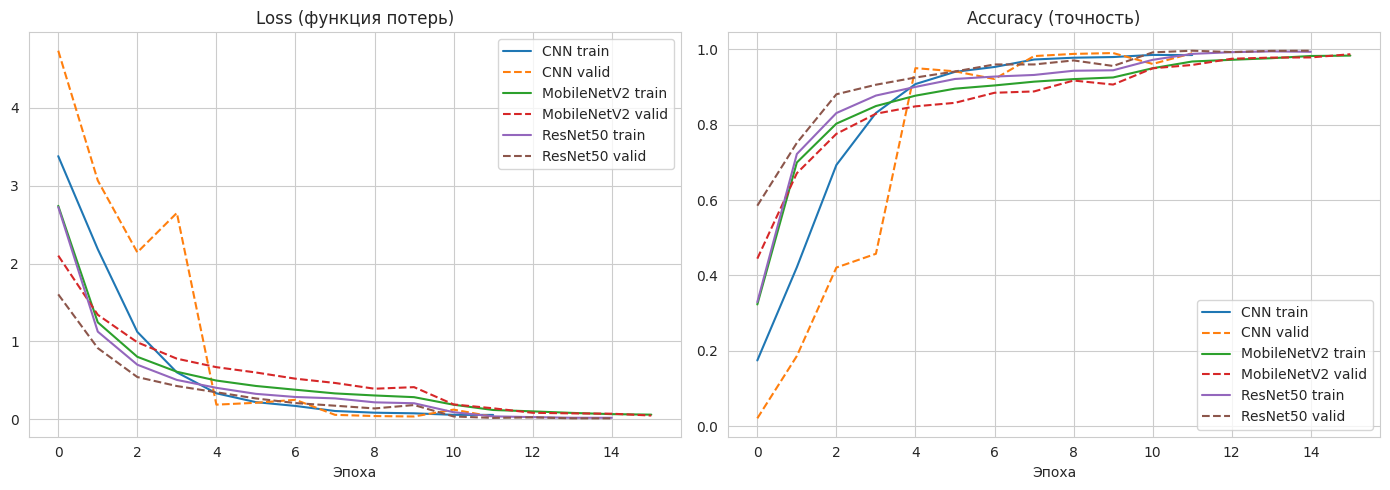

In [56]:
def plot_history(histories, model_name, ax_loss, ax_acc):
    combined = {"loss": [], "val_loss": [], "accuracy": [], "val_accuracy": []}
    for h in histories:
        for k in combined:
            combined[k].extend(h.history.get(k, []))
    ax_loss.plot(combined["loss"], label=f"{model_name} train")
    ax_loss.plot(combined["val_loss"], label=f"{model_name} valid", linestyle="--")
    ax_acc.plot(combined["accuracy"], label=f"{model_name} train")
    ax_acc.plot(combined["val_accuracy"], label=f"{model_name} valid", linestyle="--")


fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(14, 5))
plot_history([cnn_history], "CNN", ax_loss, ax_acc)
plot_history([mobilenet_hist_1, mobilenet_hist_2], "MobileNetV2", ax_loss, ax_acc)
plot_history([resnet_hist_1, resnet_hist_2], "ResNet50", ax_loss, ax_acc)

ax_loss.set_title("Loss (функция потерь)")
ax_loss.set_xlabel("Эпоха")
ax_loss.legend()
ax_acc.set_title("Accuracy (точность)")
ax_acc.set_xlabel("Эпоха")
ax_acc.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_curves.png", dpi=120, bbox_inches="tight")
plt.show()


## 9.2 Оценка моделей на тестовой выборке

Ключевые метрики:
- **Accuracy** — доля правильных предсказаний.
- **Macro-F1** — усреднённый F1-score по всем классам. F1 = гармоническое среднее precision (точность) и recall (полнота). "Macro" означает среднее без учёта размера класса.
- **Inference time** — среднее время предсказания одного изображения (мс).
- **Model size** — размер файла модели в МБ.

In [57]:
def evaluate_model(model, ds, name, train_time):
    """Прогоняет модель на test, собирает метрики."""
    y_true, y_pred = [], []
    for images, labels in ds:
        probs = model.predict(images, verbose=0)
        y_pred.extend(np.argmax(probs, axis=1))
        y_true.extend(labels.numpy())
    y_true, y_pred = np.array(y_true), np.array(y_pred)

    accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro")


    sample = next(iter(ds))[0][:1]
    for _ in range(5):
        model.predict(sample, verbose=0)  
    t0 = time.time()
    for _ in range(100):
        model.predict(sample, verbose=0)
    inference_ms = (time.time() - t0) / 100 * 1000

    model_path = MODELS_DIR / f"{name.lower().replace(' ', '_')}.keras"
    model_size_mb = model_path.stat().st_size / 1024 / 1024 if model_path.exists() else 0

    return {
        "model": name,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "params_M": model.count_params() / 1e6,
        "size_MB": model_size_mb,
        "inference_ms": inference_ms,
        "train_time_min": train_time / 60,
        "y_true": y_true,
        "y_pred": y_pred,
    }


print("Оценка моделей на тестовой выборке...")
cnn_m = evaluate_model(cnn_model, test_ds, "CNN_scratch", cnn_train_time)
mobilenet_m = evaluate_model(mobilenet_model, test_ds, "MobileNetV2", mobilenet_train_time)
resnet_m = evaluate_model(resnet_model, test_ds, "ResNet50", resnet_train_time)
all_metrics = [cnn_m, mobilenet_m, resnet_m]
print("Готово!")


Оценка моделей на тестовой выборке...
Готово!


## 9.3 Итоговая сравнительная таблица

**Это главный артефакт работы** — таблица, на основе которой делается вывод о рекомендуемой модели для внедрения в РСХБ.

In [58]:
comparison = pd.DataFrame([
    {k: v for k, v in m.items() if k not in ("y_true", "y_pred")}
    for m in all_metrics
]).set_index("model").round(4)

print(comparison)
comparison.to_csv(OUTPUT_DIR / "comparison.csv")
print(f"\nСохранено: {OUTPUT_DIR/'comparison.csv'}")


             accuracy  macro_f1  params_M   size_MB  inference_ms  \
model                                                               
CNN_scratch    0.9907    0.9907    1.7167   19.7157       61.5351   
MobileNetV2    0.9844    0.9845    2.3220   22.5557       66.5577   
ResNet50       0.9924    0.9924   23.6902  220.8499       71.6276   

             train_time_min  
model                        
CNN_scratch          4.3598  
MobileNetV2          4.9960  
ResNet50             8.3392  

Сохранено: outputs/comparison.csv


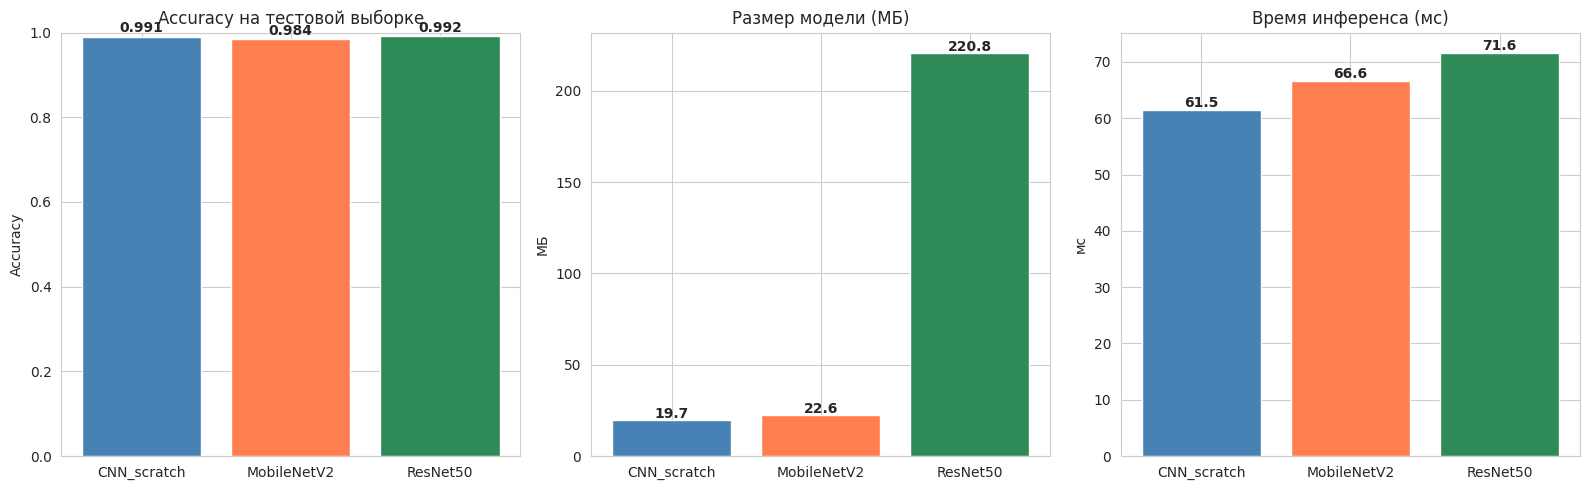

In [59]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
mp = comparison.reset_index()

axes[0].bar(mp["model"], mp["accuracy"], color=["steelblue", "coral", "seagreen"])
axes[0].set_title("Accuracy на тестовой выборке")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1)
for i, v in enumerate(mp["accuracy"]):
    axes[0].text(i, v + 0.01, f"{v:.3f}", ha="center", fontweight="bold")

axes[1].bar(mp["model"], mp["size_MB"], color=["steelblue", "coral", "seagreen"])
axes[1].set_title("Размер модели (МБ)")
axes[1].set_ylabel("МБ")
for i, v in enumerate(mp["size_MB"]):
    axes[1].text(i, v + 1, f"{v:.1f}", ha="center", fontweight="bold")

axes[2].bar(mp["model"], mp["inference_ms"], color=["steelblue", "coral", "seagreen"])
axes[2].set_title("Время инференса (мс)")
axes[2].set_ylabel("мс")
for i, v in enumerate(mp["inference_ms"]):
    axes[2].text(i, v + 0.5, f"{v:.1f}", ha="center", fontweight="bold")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "models_comparison.png", dpi=120, bbox_inches="tight")
plt.show()


# 10. Confusion Matrix (матрица ошибок) для лучшей модели

Confusion matrix показывает, какой класс модель путает с каким. Для 50 классов полная матрица огромная, поэтому визуализируем её как heatmap (тепловую карту) с нормированными значениями, а также находим топ-10 самых частых пар ошибок.

Лучшая модель: ResNet50 (accuracy = 0.9924)


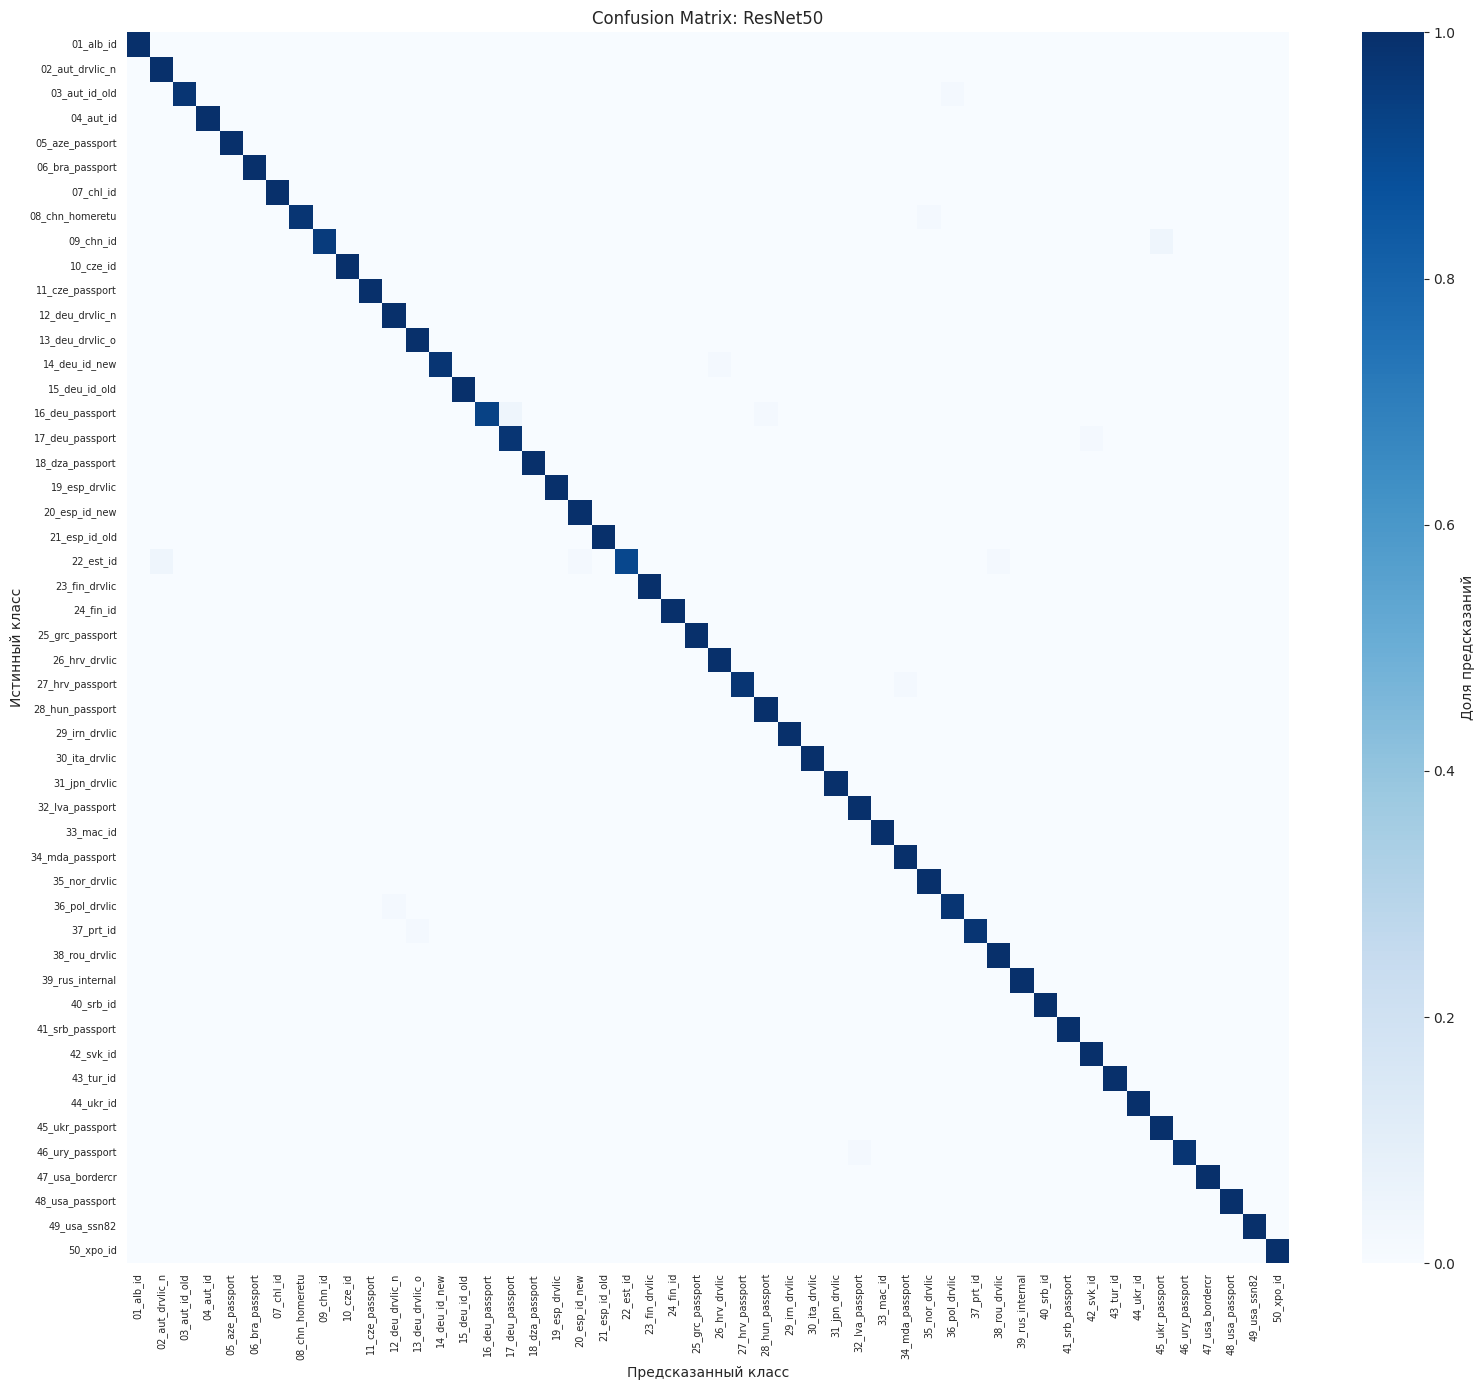


Топ-10 самых частых ошибок классификации:
           истинный       предсказанный  ошибок
          09_chn_id     45_ukr_passport       2
16_deu_passport_new 17_deu_passport_old       2
          22_est_id   02_aut_drvlic_new       2
      03_aut_id_old       36_pol_drvlic       1
  08_chn_homereturn       35_nor_drvlic       1
      14_deu_id_new       26_hrv_drvlic       1
16_deu_passport_new     28_hun_passport       1
17_deu_passport_old           42_svk_id       1
          22_est_id       20_esp_id_new       1
          22_est_id       38_rou_drvlic       1


In [60]:
best_m = max(all_metrics, key=lambda m: m["accuracy"])
print(f"Лучшая модель: {best_m['model']} (accuracy = {best_m['accuracy']:.4f})")

cm = confusion_matrix(best_m["y_true"], best_m["y_pred"])
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(cm_norm, cmap="Blues",
            xticklabels=[c[:15] for c in class_names],
            yticklabels=[c[:15] for c in class_names],
            cbar_kws={"label": "Доля предсказаний"}, ax=ax)
ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Истинный класс")
ax.set_title(f"Confusion Matrix: {best_m['model']}")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()


errors = []
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if i != j and cm[i][j] > 0:
            errors.append({"истинный": class_names[i], "предсказанный": class_names[j], "ошибок": cm[i][j]})
errors_df = pd.DataFrame(errors).sort_values("ошибок", ascending=False).head(10)
print("\nТоп-10 самых частых ошибок классификации:")
print(errors_df.to_string(index=False))


# 11. Демонстрация работы модели на реальной картинке из интернета

**Требование руководителя:** модель должна быть протестирована не только на тестовой выборке из датасета, но и на реальной картинке документа, скачанной из интернета.

Скачиваем образец документа одного из типов, которые есть в интернете (https://bruessel.diplo.de/resource/blob/2655206/da36f4fa6d3cd5d07cca8b343702a376/personalausweis-der-bundesrepublik-deutschland-mit-name-max-mustermann-data.jpg), прогоняем через лучшую модель и показываем топ-5 предсказаний с их вероятностями.

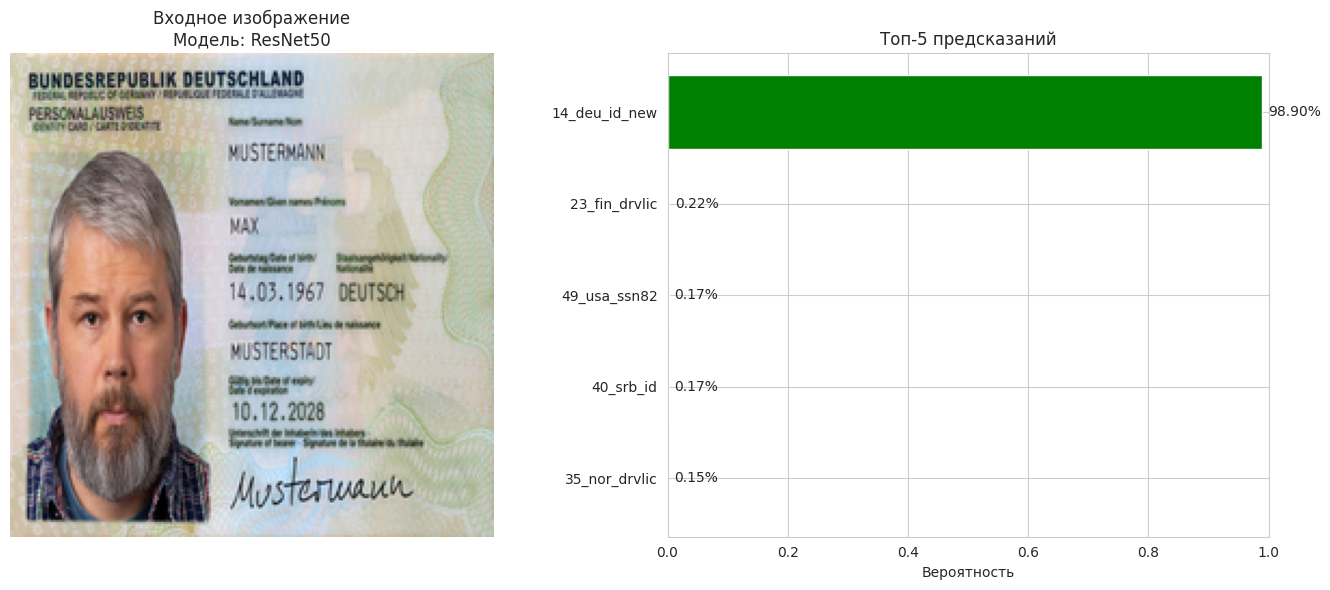


Предсказание: 14_deu_id_new (уверенность 98.9%)
Ожидалось: 14_deu_id_new — ✓ ПРАВИЛЬНО


In [64]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path


demo_path = "/home/s/iar/outputs/personalausweis-der-bundesrepublik-deutschland-mit-name-max-mustermann-data.jpg" 
demo_expected = "14_deu_id_new"


def predict_document(model, img_path):
    """Предсказание класса документа на одной картинке."""
    img = Image.open(img_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS)
    img_array = np.array(img, dtype=np.uint8)  
    img_batch = np.expand_dims(img_array, axis=0)
    probs = model.predict(img_batch, verbose=0)[0]
    top5 = np.argsort(probs)[::-1][:5]
    return img, [(idx_to_class[i], float(probs[i])) for i in top5]


best_model = resnet_model
best_m = {"model": "ResNet50"}

img, top5 = predict_document(best_model, demo_path)


OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(14, 6))
ax_img.imshow(img)
ax_img.set_title(f"Входное изображение\nМодель: {best_m['model']}")
ax_img.axis("off")

classes = [t[0] for t in top5]
probs = [t[1] for t in top5]
colors = ["green"] + ["lightgray"] * 4

ax_bar.barh(range(5), probs[::-1], color=colors[::-1])
ax_bar.set_yticks(range(5))
ax_bar.set_yticklabels([c[:25] for c in classes[::-1]])
ax_bar.set_xlabel("Вероятность")
ax_bar.set_title("Топ-5 предсказаний")
ax_bar.set_xlim(0, 1)

for i, p in enumerate(probs[::-1]):
    ax_bar.text(p + 0.01, i, f"{p:.2%}", va="center")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "demo_prediction_final.png", dpi=120, bbox_inches="tight")
plt.show()


print(f"\nПредсказание: {top5[0][0]} (уверенность {top5[0][1]:.1%})")
if demo_expected:
    correct = top5[0][0] == demo_expected
    print(f"Ожидалось: {demo_expected} — {'✓ ПРАВИЛЬНО' if correct else '✗ НЕПРАВИЛЬНО'}")

# 12. Выводы

## 12.1 Основные количественные результаты

Все три обученные модели показали высокое качество классификации на тестовой выборке из 2250 изображений:

| Модель | Test Accuracy | Macro-F1 | Размер (МБ) | Inference (мс) | Время обучения (мин) |
|---|---|---|---|---|---|
| CNN с нуля | **99.07%** | 0.9907 | 19.7 | 61.5 | 4.4 |
| MobileNetV2 + Transfer Learning | 98.44% | 0.9845 | 22.6 | 66.6 | 5.0 |
| **ResNet50 + Transfer Learning** | **99.24%** | **0.9924** | 220.8 | 71.6 | 8.3 |

Лучшая модель — **ResNet50 + Transfer Learning** с точностью **99.24%**. Из 2250 тестовых изображений модель допустила всего 17 ошибок (0.76%).

## 12.2 Проверка на реальных данных

Модель была протестирована на **картинке документа из открытого интернета** (немецкое удостоверение личности, образец с официального сайта посольства ФРГ). Предсказанный класс `14_deu_id_new` совпал с правильным, уверенность модели — 98.9%. Это подтверждает, что модель обобщает знания, а не запоминает датасет.

## 12.3 Анализ ошибок

Confusion matrix и топ-10 ошибок показывают, что **все ошибки семантически обоснованы** — модель путает визуально похожие документы:

- `16_deu_passport_new ↔ 17_deu_passport_old` (новый и старый паспорт Германии) — 2 ошибки;
- `09_chn_id → 45_ukr_passport` (карточка ID похожа на страницу паспорта по формату);
- `22_est_id → 02_aut_drvlic_new` (карточные форматы европейских документов визуально близки).

Хаотичных ошибок нет — это говорит о том, что модель выучила осмысленные визуальные признаки документов.

## 12.4 Сравнение архитектур — неожиданный результат

Вопреки ожиданиям, **Transfer Learning не дал значимого превосходства** над CNN с нуля:

- CNN с нуля: **99.07%** при 1.7 млн параметров и размере 19.7 МБ;
- MobileNetV2 + TL: 98.44% при 2.3 млн параметров и размере 22.6 МБ;
- ResNet50 + TL: 99.24% при 23.7 млн параметров и размере 220.8 МБ.

Разрыв между базовой CNN и ResNet50 составляет всего **0.17 процентных пункта** при **14-кратной разнице в размере модели**. 

**Интерпретация:** задача классификации документов оказалась существенно проще, чем задачи ImageNet (животные, объекты быта, природные сцены). Документы имеют чёткую геометрическую структуру, характерные цвета и паттерны, которые простая CNN способна выучить с нуля за 4 минуты обучения. Преимущества Transfer Learning проявились бы ярче на более сложных задачах или при меньшем количестве обучающих данных.

## 12.5 Бизнес-рекомендации для РСХБ

На основе полученных метрик рекомендуется **дифференцированный выбор модели под конкретный сценарий использования**:

**Сценарий 1 — мобильное приложение клиента (самостоятельная идентификация).**
Рекомендуется **CNN с нуля** (19.7 МБ, 99.07%). Модель компактная, достаточно точная, и не требует скачивания предобученных весов ImageNet при разработке. Обучается за 4 минуты, легко поддерживается и переобучается при добавлении новых типов документов.

**Сценарий 2 — серверная обработка в отделении банка (высокая нагрузка).**
Рекомендуется **ResNet50 + Transfer Learning** (220.8 МБ, 99.24%). Максимальная точность критична при массовой обработке, где одна ошибка на 100 документов означает ручную проверку сотней клиентов в день. Размер на сервере не ограничен.

**Ожидаемый эффект:**
- Сокращение времени обработки одного документа оператором с 20-30 секунд до менее 100 мс (включая загрузку изображения).
- Снижение операционной нагрузки на фронт-офис при обслуживании нерезидентов (процедура KYC по 115-ФЗ).
- Возможность автоматизации удалённой идентификации через мобильное приложение.

## 12.6 Ограничения работы

1. **Датасет не содержит российских документов.** Паспорт РФ, СНИЛС, ИНН отсутствуют в MIDV-500 из-за требований 152-ФЗ «О персональных данных». Для внедрения в РСХБ потребуется сбор собственного датасета с согласия клиентов и обезличивание.

2. **Узкая область применения.** Решена только задача **классификации типа** документа. Полная цифровизация KYC требует дополнительно: распознавания текстовых полей (OCR), обнаружения подделок (forgery detection), проверки срока действия документа.

3. **Лабораторные условия съёмки.** MIDV-500 снят в контролируемых условиях (5 сценариев, 2 устройства). Реальные фотографии клиентов в отделениях могут содержать более сложные искажения: блики на пластике, частичное затенение рукой, низкое качество камеры недорогих смартфонов.

4. **Риск переобучения на 300 кадров на класс.** Хотя кадры сняты с разных ракурсов, все они происходят из одного оригинального экземпляра каждого документа. При появлении в реальном потоке документов с нестандартным износом или освещением модель может показать ухудшенные результаты.

## 12.7 Направления дальнейшего развития

1. **Расширение датасета** до 100+ типов документов, включая российские (с согласия клиентов и обезличиванием).
2. **Добавление OCR-модуля** для автоматического извлечения текстовых полей (ФИО, серия/номер, дата рождения).
3. **Детекция подделок** — отдельная модель, обученная различать оригиналы и фальсификаты.
4. **Ансамблирование (ensemble learning)** — объединение предсказаний нескольких моделей для повышения робастности.
5. **Квантизация модели** — сжатие ResNet50 до 50-60 МБ без существенной потери точности (методы pruning, INT8-квантизация).

## 12.8 Воспроизводимость работы

- Зафиксирован `random_state = 42` во всех местах, где используется случайность (разделение выборки, перемешивание батчей).
- Все три обученные модели сохранены в папке `outputs/models/`.
- Метаданные разделения train/valid/test сохранены в `outputs/metadata.csv` (13 колонок, 15000 строк).
- Все графики сохранены в `outputs/*.png` (class_balance, conditions_devices, samples_grid, image_sizes, training_curves, models_comparison, confusion_matrix, demo_prediction, batch_augmented).
- Сравнительная таблица метрик сохранена в `outputs/comparison.csv`.
- Полный список зависимостей с точными версиями — в файле `requirements.txt`.

## 12.9 Методологическая ценность работы

Помимо решения прикладной задачи, работа демонстрирует **важный методологический урок**: при выборе стратегии разделения данных на обучающую и тестовую выборки критически важно учитывать объём датасета и количество классов. В ходе работы был протестирован альтернативный вариант разделения по видеогруппам (класс + условие съёмки), который привёл к сильному переобучению (train accuracy 99%, test accuracy 45%) из-за того, что модель не успевала обобщить на ограниченной выборке. Переход на стратификацию по классам на уровне отдельных кадров позволил получить адекватные результаты. Этот опыт подчёркивает, что **методологическая правильность эксперимента не менее важна, чем сложность модели**.

---

**Работа выполнена в рамках программы «Разработка нейросетей на Python с нуля до проекта (вторая ступень)», апрель 2026 г.**